[3. 4. 0.]


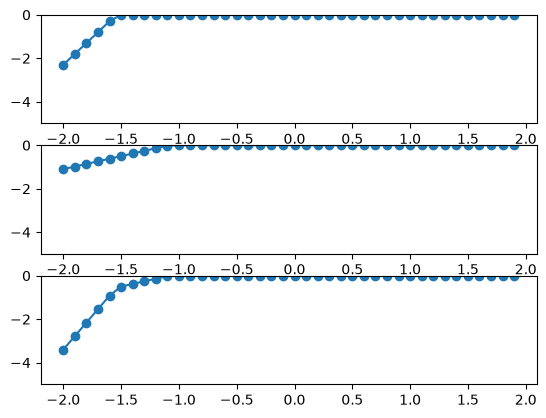

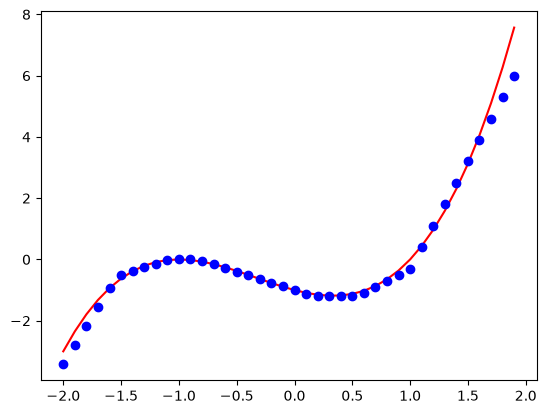

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def relu(x):
    x[x<0]= 0.0
    return x

a = np.array([3., 4.0, -5.0])
print(relu(a))

x = np.arange(-2,2,0.1)

n_1 = relu(-5*x - 7.7)

n_2 = relu(-1.2*x - 1.3)

n_3 = relu(1.2*x + 1)

n_4 = relu(1.2*x - .2)

n_5 = relu(2*x - 1.1)

n_6 = relu(5*x - 5)

fig, axes = plt.subplots(3, 1)
for ax in axes.ravel():
    ax.set_ylim(-5, 0)
plt.subplot(3,1,1)
plt.plot(x,-n_1,'o-')
plt.subplot(3,1,2)
plt.plot(x,-n_2,'o-')
plt.subplot(3,1,3)
plt.plot(x,-n_1-n_2,'o-')

z = -n_1 - n_2 - n_3 + n_4 + n_5 + n_6

f = np.power(x,3) + np.power(x,2) - x  - 1

plt.figure()
plt.plot(x,f,'r')
plt.plot(x,z,'bo')
plt.show()


True Pattern Location Start: 75
Detected Pattern Location Start: 75


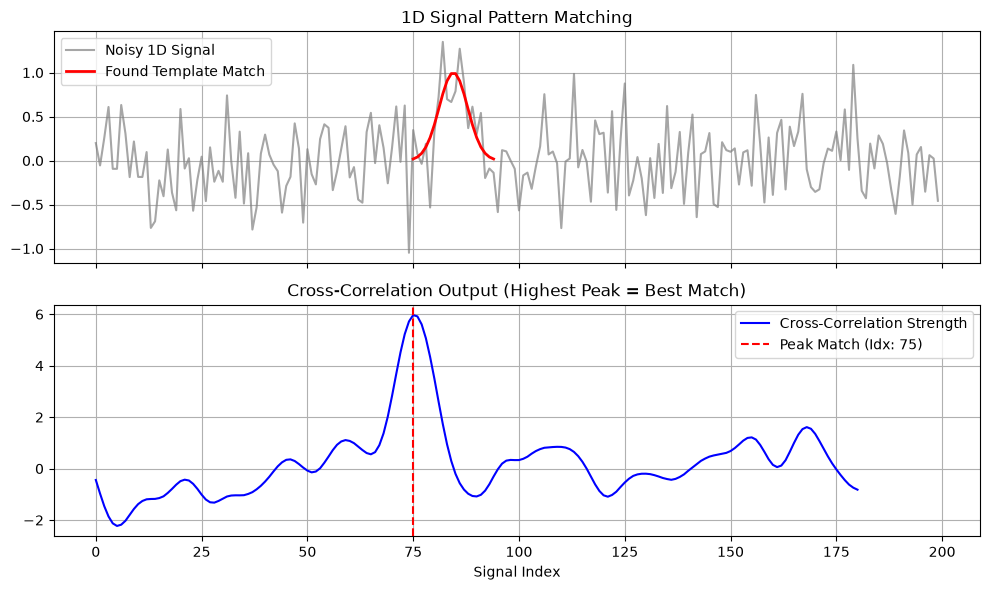

In [3]:
import matplotlib.pyplot as plt
from scipy.signal import correlate
import numpy as np

# 1. Define the 1D signal and the pattern template
np.random.seed(42)  # For reproducible noise
signal_length = 200
pattern_length = 20
pattern_start_idx = 75

# Create a distinct pattern (a Gaussian pulse shape)
x_pattern = np.linspace(-2, 2, pattern_length)
template_pattern = np.exp(-x_pattern**2)

# Create a noisy baseline signal
noise = np.random.normal(0, 0.4, signal_length)
main_signal = noise.copy()

# Inject the pattern into the main signal at the start index
main_signal[pattern_start_idx : pattern_start_idx + pattern_length] += template_pattern

# 2. Perform Pattern Matching via Cross-Correlation
# We use mode='valid' so the correlation vector matches the valid overlapping regions
correlation = correlate(main_signal, template_pattern, mode='valid')

# The peak index of the correlation array tells us where the template starts
detected_start_idx = np.argmax(correlation)

print(f"True Pattern Location Start: {pattern_start_idx}")
print(f"Detected Pattern Location Start: {detected_start_idx}")

# 3. Plot the Results
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Top Plot: The Signal and Template
ax1.plot(main_signal, label="Noisy 1D Signal", color="gray", alpha=0.7)
ax1.plot(
    range(detected_start_idx, detected_start_idx + pattern_length), 
    template_pattern, 
    label="Found Template Match", 
    color="red", 
    linewidth=2
)
ax1.set_title("1D Signal Pattern Matching")
ax1.legend()
ax1.grid(True)

# Bottom Plot: The Correlation Strength
ax2.plot(correlation, label="Cross-Correlation Strength", color="blue")
ax2.axvline(detected_start_idx, color="red", linestyle="--", label=f"Peak Match (Idx: {detected_start_idx})")
ax2.set_title("Cross-Correlation Output (Highest Peak = Best Match)")
ax2.set_xlabel("Signal Index")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()
